# Flat AB comparison: ZShooter and X-shooter

Start with a centered **AB 20 flat $f_
u$ continuum**, as in `zshooter_performance.ipynb`. Both instruments see the **same atmospheric transmission, continuum, and PALACE airglow spectra**, at airmass 1.3 and 0.7 arcsec seeing. Telescope collecting area, optics, slit, detector, and ADC remain instrument inputs. This isolates the instrumental comparison from a change of sky model or observing site.

The default X-shooter configuration uses the manual's 1.0/0.9/0.9 arcsec UVB/VIS/NIR slits, slow CCD readout, and 1x2 CCD binning (spectral direction); the NIR array is unbinned. It is a faint-source comparison setting, **not a reconstruction of the exact Pian et al. exposure setup**. ZShooter uses a 0.70 arcsec slit and its current qCCD/APD design specifications. Change these explicit settings below for engineering comparisons.

The extraction is a noise-free expectation forecast with a spatial boxcar selected to within 0.01 mag of the best expected 5-sigma sensitivity. Native pixels are extracted without rectification. Spectral degradation and binning propagate covariance. OH sample selection is a separate optional calculation. Full-frame noisy readouts are retained for inspection; their formats and native resolutions differ.

See [the validation assessment](../docs/xshooter-validation.md) for the distinction between shared numerical checks, calibrated X-shooter inputs, and independent observational validation. A good match to a fitted response curve does not validate ZShooter's proposed throughput or detector specifications.


In [11]:
from pathlib import Path
from time import perf_counter
from copy import deepcopy
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from scipy import sparse
from synphot import SourceSpectrum, Empirical1D
from synphot.units import PHOTLAM
import scopesim as sim
from scopesim.source.source_templates import ab_spectrum
from scopesim.utils import from_currsys
from scopesim.effects import SelectorWheel, SpectralTraceList
from zs_scopesim_tools.helpers import configure_irdb_path, warning_prevent_sync_alt_ra_dec, disable_scopesim_progress_bars, set_scopesim_log_level

workspace = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'env/zshooter-stack.toml').exists())
irdb = Path(configure_irdb_path())
output = workspace / 'validation/xshooter/data/comparison'
output.mkdir(parents=True, exist_ok=True)
set_scopesim_log_level('warning')
print(sim.__version__, sim.__file__)

0.12.1.dev6 /Users/jibailey/src/scopesim/scopesim/__init__.py


In [2]:
AB_MAG = 20.
DIT = 300.
NDIT = 12
SEEING = .7
AIRMASS = 1.3
TARGET_R = 1000.
SAMPLES_PER_FWHM = 4
SKY_VARIANCE_FACTOR = 2.  # Equal-time nod subtraction: one on-source hour, sky from the other nods.
XSHOOTER_PRESET = 'faint_continuum'
XSHOOTER_SETTINGS = {
    'faint_continuum': {'!INST.uvb_curr_slit': '1.0', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.9', '!DET.biny_uvb': 2, '!DET.biny_vis': 2},
    'higher_resolution': {'!INST.uvb_curr_slit': '0.8', '!INST.vis_curr_slit': '0.9', '!INST.nir_curr_slit': '0.6', '!DET.biny_uvb': 1, '!DET.biny_vis': 1},
}
flat_ab = ab_spectrum(mag=AB_MAG)
source = sim.Source(x=[0.], y=[0.], ref=[0], weight=[1.], spectra=[flat_ab])
properties = {'!OBS.airmass': AIRMASS, '!OBS.seeing': SEEING, '!OBS.brightness': 'dark', '!OBS.mjdobs': 60310.25, '!SIM.random.seed': 62419}
z_properties = properties | {'!INST.vis_curr_slit': .7, '!INST.nir_curr_slit': .7, '!INST.include_diffuse_emissivity': False, '!ATMO.skycalc_timeout': 60.}
x_properties = properties | XSHOOTER_SETTINGS[XSHOOTER_PRESET]
for arm in ('blue', 'green', 'red', 'yj', 'h', 'k'):
    z_properties.update({f'!OBS.dit_{arm}': DIT, f'!OBS.ndit_{arm}': NDIT})
for arm in ('uvb', 'vis', 'nir'):
    x_properties.update({f'!OBS.dit_{arm}': DIT, f'!OBS.ndit_{arm}': NDIT})

started = perf_counter()
zcmds = sim.UserCommands(use_instrument='ZShooter_v2', set_modes=['SPEC'], properties=z_properties)
warning_prevent_sync_alt_ra_dec(zcmds)
ztrain = sim.OpticalTrain(zcmds)
xcmds = sim.UserCommands(use_instrument='XSHOOTER', set_modes=['SPEC'], properties=x_properties, ignore_effects=['skycalc_atmosphere'])
warning_prevent_sync_alt_ra_dec(xcmds)
xtrain = sim.OpticalTrain(xcmds)
# Reuse the evaluated atmospheric curves and their observing parameters, without a second site query.
for name in ('atmo_transmission', 'continuum_emission', 'airglow_and_interline_continuum'):
    xtrain.optics_manager.add_effect(deepcopy(ztrain[name]))
trains = {'ZShooter': ztrain, 'XSHOOTER': xtrain}
print(f'Setup {perf_counter() - started:.1f} s; one common sky model, {DIT * NDIT / 3600:.1f} h on source.')


py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:170: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  fov = thetrace.fov_grid()

py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:225: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  vol = spt.fov_grid()

py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:170: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  fov = thetrace.fov_grid()

Setup 9.8 s; one common sky model, 1.0 h on source.


## Full-frame observations and noise convention

Each instrument needs a source-plus-sky observation and an empty-sky observation to separate expected source counts from background. These are four full-frame simulations, timed individually below; the notebook's total time is therefore longer than one simulation. No detector windows are used. ZShooter's diffuse-emissivity option stays at the existing performance notebook's setting (`False`); X-shooter's measured NIR background component remains enabled. This is a design-versus-calibrated-input limitation to examine in thermal-background engineering comparisons.

Forecast arrays are accumulated electrons over all integrations, extracted from the simulator's image planes through its detector geometry and charge/software binning effects. This avoids conflating the CCD summed ADU products with X-shooter's NIR averaged ADU product. Actual readout FITS files retain those native conventions. For equal-time nod subtraction the background variance is $2(B+D+N_{\rm DIT}\sigma_r^2)$, while source variance is $S$. The on-source exposure is one hour, without overheads. Detector systematics, flat-field errors, imperfect sky subtraction, and source confusion are not included.


In [3]:
from zs_scopesim_tools.comparison import detector_rates, detector_noise, trace_pixel_grid, boxcar_sum, choose_boxcar, limiting_abmag, gaussian_bin_matrix, line_width

frames = {}
timings = []
for name, train in trains.items():
    started = perf_counter()
    with disable_scopesim_progress_bars():
        train.observe(source)
    observed = perf_counter()
    readouts = train.readout()
    finished = perf_counter()
    total_rates = detector_rates(train)
    noise = [detector_noise(train, index) for index in range(len(readouts))]
    for index, readout in enumerate(readouts):
        readout.writeto(output / f'{name}_detector_{index}.fits', overwrite=True)
    timings.append((name, 'source + sky', observed - started, finished - observed))
    print(f'{name} source + sky: {observed - started:.1f} s; readout {finished - observed:.1f} s', flush=True)
    started = perf_counter()
    with disable_scopesim_progress_bars():
        train.observe(None)
    background_rates = detector_rates(train)
    timings.append((name, 'sky', perf_counter() - started, 0.))
    # A distinct stream is essential for an independent sky exposure at a fixed root seed.
    sky_readouts = train.readout(roid=1)
    for index, readout in enumerate(sky_readouts):
        readout.writeto(output / f'{name}_sky_{index}.fits', overwrite=True)
    frames[name] = []
    for index, (total, background, (exptime, dark, read_variance)) in enumerate(zip(total_rates, background_rates, noise)):
        signal = (total - background) * exptime
        assert signal.min() >= -1.e-8 * signal.max(), 'Background subtraction changed the optical model.'
        frames[name].append({'source': signal, 'background': background * exptime, 'dark': dark, 'read_variance': read_variance, 'exptime': exptime})
    print(f'{name} sky: {timings[-1][2]:.1f} s; shapes {[frame["source"].shape for frame in frames[name]]}', flush=True)
    del total_rates, background_rates, readouts, sky_readouts
    gc.collect()
timing_table = pd.DataFrame(timings, columns=['instrument', 'observation', 'observe_s', 'readout_s'])
timing_table.to_csv(output / 'timings.csv', index=False)
display(timing_table)


py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:225: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  vol = spt.fov_grid()

ZShooter source + sky: 44.4 s; readout 1.5 s
py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:225: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  vol = spt.fov_grid()

ZShooter sky: 41.7 s; shapes [(4096, 2048), (4096, 2048), (4096, 2048), (2048, 2048), (2048, 2048), (2048, 2048)]
py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:225: DeprecationWarning: The fov_grid method is deprecated and will be removed in a future release.
  vol = spt.fov_grid()

XSHOOTER source + sky: 102.2 s; readout 0.5 s
py.warnings - WARNING: /Users/jibailey/src/scopesim/scopesim/effects/spectral_trace_list.py:225: DeprecationWarning: The fov_grid method is depreca

,instrument,observation,observe_s,readout_s
0,ZShooter,source + sky,44.379151,1.518888
1,ZShooter,sky,41.720871,0.000000
2,XSHOOTER,source + sky,102.162826,0.522023
3,XSHOOTER,sky,98.784456,0.000000


In [4]:
extracted = {}
aperture_rows = []
for name, train in trains.items():
    trace_list, = train.optics_manager.get_all(SpectralTraceList)
    extracted[name] = {}
    used_pixels = [np.zeros(frame['source'].shape, dtype=bool) for frame in frames[name]]
    for trace_id, trace in trace_list.spectral_traces.items():
        index, axis, pixels, centers, edges = trace_pixel_grid(train, trace_id)
        frame = frames[name][index]
        middle = (edges[0] + edges[-1]) / 2
        spatial_axis = 'y' if axis == 'x' else 'x'
        aperture = train.trace_detector_coordinates(xi=np.array([-1.5, 1.5]) * SEEING * u.arcsec, wavelengths={trace_id: middle.reshape(1)})
        max_width = int(np.ceil(np.ptp(aperture[f'detector_{spatial_axis}'].to_value(u.pixel))))
        spatial_size = frame['source'].shape[0 if axis == 'x' else 1]
        inside = (centers >= max_width / 2) & (centers < spatial_size - max_width / 2)
        valid = np.flatnonzero(inside)
        assert len(valid) > 0 and np.all(np.diff(valid) == 1), (name, trace_id, 'Split disconnected detector coverage explicitly.')
        first, last = valid[0], valid[-1]
        pixels, centers, edges = pixels[first:last + 1], centers[first:last + 1], edges[first:last + 2]
        noise_per_pixel = frame['dark'] + frame['read_variance']
        widths = choose_boxcar(frame['source'], frame['background'], axis, pixels, centers, max_width, noise_per_pixel, SKY_VARIANCE_FACTOR, AB_MAG)
        signal = boxcar_sum(frame['source'], axis, pixels, centers, widths)
        sky = boxcar_sum(frame['background'], axis, pixels, centers, widths)
        variance_background = SKY_VARIANCE_FACTOR * (sky + widths * noise_per_pixel)
        starts = np.floor(centers - (widths - 1) / 2 + .5).astype(int)
        for offset in range(widths.max()):
            keep = offset < widths
            yy, xx = (starts[keep] + offset, pixels[keep]) if axis == 'x' else (pixels[keep], starts[keep] + offset)
            assert not used_pixels[index][yy, xx].any(), 'Two extracted orders share detector pixels.'
            used_pixels[index][yy, xx] = True
        extracted[name][trace_id] = {'index': index, 'axis': axis, 'pixels': pixels, 'centers': centers, 'edges': edges, 'widths': widths, 'signal': signal, 'variance_source': signal, 'variance_background': variance_background}
        aperture_rows.append((name, trace_id, index, edges[0].value, edges[-1].value, widths.min(), widths.max(), signal.sum()))
    del used_pixels
aperture_table = pd.DataFrame(aperture_rows, columns=['instrument', 'trace', 'detector', 'wave_min_um', 'wave_max_um', 'boxcar_min_pixel', 'boxcar_max_pixel', 'source_e'])
aperture_table.to_csv(output / 'apertures.csv', index=False)
display(aperture_table.groupby('instrument').agg(traces=('trace', 'count'), min_width=('boxcar_min_pixel', 'min'), max_width=('boxcar_max_pixel', 'max'), source_e=('source_e', 'sum')))


,traces,min_width,max_width,source_e
instrument,,,,
XSHOOTER,43,1,7,2.321917e+07
ZShooter,127,4,7,6.223797e+07


## Measure the simulated line profiles

One narrow input line near each order's central wavelength measures the detector-integrated native profile. The line has intrinsic $R=200{,}000$ and is sampled at more than ten points per FWHM. Its finite width remains in the reported result. For speed, only narrow wavelength intervals around these lines are propagated, through the existing configured FOV geometry and full detector arrays. This is a spectral calibration probe, not a detector sub-window.

The controlled line probe disables additive backgrounds and source-stage transmission curves; it retains the configured seeing, slit, ADC, trace mapping, optical LSF, and binning. FWHM and second moment are both measured. The common-resolution kernel uses the second moment, then the achieved FWHM is measured again. One point per order does not establish wavelength-by-wavelength optical fidelity.

In [5]:
from scopesim.optics.fov import FieldOfView3D

line_rows = []
line_profiles = {}
for name, train in trains.items():
    started = perf_counter()
    original_fovs = train.fov_manager.fovs
    original_effects = [(effect, effect.include) for effect in train.optics_manager.source_effects]
    for effect, included in original_effects:
        effect.include = False
    if name == 'XSHOOTER':
        original_effects.append((train['nir_stray_light'], train['nir_stray_light'].include))
        train['nir_stray_light'].include = False
    try:
        # Orders in overlapping arms share one lamp line, avoiding an accidental close doublet.
        comb = .3 * np.exp(np.arange(220) * .01) * u.um
        line_centers = {}
        for trace_id, data in extracted[name].items():
            middle = (data['edges'][0] + data['edges'][-1]) / 2
            available = comb[(comb > data['edges'][0] * 1.003) & (comb < data['edges'][-1] * .997)]
            line_centers[trace_id] = available[np.argmin(np.abs(available - middle))]
        points, flux = [], []
        for center in np.unique([wave.to_value(u.um) for wave in line_centers.values()]) * u.um:
            sigma = center.to_value(u.AA) / (200000 * np.sqrt(8 * np.log(2)))
            grid = center.to_value(u.AA) + np.linspace(-8, 8, 161) * sigma
            points.extend(grid)
            flux.extend(np.exp(-.5 * ((grid - center.to_value(u.AA))/sigma)**2))
        order = np.argsort(points)
        line_spectrum = SourceSpectrum(Empirical1D, points=np.array(points)[order] * u.AA, lookup_table=np.array(flux)[order] * PHOTLAM, fill_value=0)
        lamps = sim.Source(x=[0.], y=[0.], ref=[0], weight=[1.], spectra=[line_spectrum])
        probes = []
        for fov in original_fovs:
            center = line_centers[fov.trace_id]
            low = max(fov.meta['wave_min'], center * .997)
            high = min(fov.meta['wave_max'], center * 1.003)
            if high <= low:
                continue
            metadata = fov.meta | {'wave_min': low, 'wave_max': high}
            probe = FieldOfView3D(fov.header.copy(), (low, high), detector_header=fov.detector_header, cmds=train.cmds, **metadata)
            probe.image_plane_id = fov.image_plane_id
            probes.append(probe)
        train.fov_manager._fovs_list = probes
        for plane in train.image_planes:
            plane.data[:] = 0
        with disable_scopesim_progress_bars():
            train.observe(lamps, update=False)
        rates = detector_rates(train)
        line_profiles[name] = {}
        for trace_id, data in extracted[name].items():
            counts = boxcar_sum(rates[data['index']], data['axis'], data['pixels'], data['centers'], data['widths'])
            wave = (data['edges'][:-1] + data['edges'][1:]) / 2
            selected = np.abs(wave / line_centers[trace_id] - 1) < .0025
            center, sigma, fwhm = line_width(wave[selected], counts[selected])
            line_profiles[name][trace_id] = counts
            line_rows.append((name, trace_id, center.to_value(u.um), sigma.to_value(u.um), fwhm.to_value(u.um), (center / fwhm).value))
    finally:
        train.fov_manager._fovs_list = original_fovs
        for effect, included in original_effects:
            effect.include = included
    print(f'{name} line calibration: {perf_counter() - started:.1f} s', flush=True)
line_table = pd.DataFrame(line_rows, columns=['instrument', 'trace', 'wavelength_um', 'sigma_um', 'fwhm_um', 'native_R'])
line_table.to_csv(output / 'line_widths.csv', index=False)
display(line_table.groupby('instrument')['native_R'].agg(['min', 'median', 'max']))


ZShooter line calibration: 8.5 s
XSHOOTER line calibration: 10.7 s


,min,median,max
instrument,,,
XSHOOTER,5312.691141,6221.151447,9392.198907
ZShooter,13887.553468,20079.003970,23985.239027


## Common resolution and limiting magnitude

Counts are redistributed with a Gaussian in $\log\lambda$ and integrated into bins at four samples per target FWHM. The extra Gaussian variance subtracts the measured native line variance and the output-bin top-hat variance from the target variance. We retain $C=W\,\mathrm{diag}(V)\,W^T$. A resolution-element measurement sums four neighboring bins, including their covariance; treating those bins as independent would overstate sensitivity.

Order overlap is handled conservatively: at each resolution element, use the single order with the best expected 5-sigma limit. No gain from coadding overlapping orders or arms is assumed. The throughput plot is the detected, boxcar-extracted fraction for that selected order, including common atmosphere and slit losses, divided by photons incident on each telescope's configured collecting area. Instrument comparisons include those different collecting areas in the sensitivity calculation.

The limiting magnitude solves $a^2 S^2=25(aV_s+V_b)$, with $m_5=20-2.5\log_{10}a$. Flat AB makes this normalization identical across wavelength. Strong telluric bands and detector/order boundaries remain visible.


At the default sampling, interpolating the half-height crossings of the binned line probes gives $R_{\rm FWHM}\simeq959$--964 for both instruments; the variance-equivalent Gaussian width is R=1000 by construction. The difference is visible in the measurements rather than hidden by the target label. The paired profiles agree much more closely than either rounded target. Per-order source and background covariance matrices are saved as sparse NPZ files alongside the CSV tables. They are local generated artifacts, not committed detector products.


In [6]:
log_step = 1 / (TARGET_R * SAMPLES_PER_FWHM)
bin_count = int(np.log(2.5 / .3) / log_step) // SAMPLES_PER_FWHM * SAMPLES_PER_FWHM
common_edges = .3 * np.exp(np.arange(bin_count + 1) * log_step) * u.um
common_centers = np.sqrt(common_edges[:-1] * common_edges[1:])
resolution_edges = common_edges[::SAMPLES_PER_FWHM]
resolution_wave = np.sqrt(resolution_edges[:-1] * resolution_edges[1:])
sum_resolution_bins = sparse.csr_matrix((np.ones(bin_count), (np.arange(bin_count) // SAMPLES_PER_FWHM, np.arange(bin_count))), shape=(bin_count // SAMPLES_PER_FWHM, bin_count))
common = {}
comparison_rows = []
common_line_rows = []
for name, train in trains.items():
    common[name] = {}
    order_rows = []
    for trace_id, data in extracted[name].items():
        measured = line_table[(line_table.instrument == name) & (line_table.trace == trace_id)].iloc[0]
        native_sigma_log = measured.sigma_um / measured.wavelength_um
        target_sigma_log = 1 / (TARGET_R * np.sqrt(8 * np.log(2)))
        extra_variance = target_sigma_log**2 - native_sigma_log**2 - log_step**2 / 12
        assert extra_variance > 0, (name, trace_id, 'Native resolution is already broader than the target.')
        extra_sigma = np.sqrt(extra_variance)
        native_wave = (data['edges'][:-1] + data['edges'][1:]) / 2
        operator = gaussian_bin_matrix(native_wave, common_edges, extra_sigma)
        signal = operator @ data['signal']
        covariance_source = operator.multiply(data['variance_source']) @ operator.T
        covariance_background = operator.multiply(data['variance_background']) @ operator.T
        sparse.save_npz(output / f'{name}_{trace_id}_source_covariance.npz', covariance_source)
        sparse.save_npz(output / f'{name}_{trace_id}_background_covariance.npz', covariance_background)
        common[name][trace_id] = {'operator': operator, 'signal': signal, 'covariance_source': covariance_source, 'covariance_background': covariance_background}
        resolution_operator = sum_resolution_bins @ operator
        resolution_signal = resolution_operator @ data['signal']
        resolution_source_variance = resolution_operator.power(2) @ data['variance_source']
        resolution_background_variance = resolution_operator.power(2) @ data['variance_background']
        complete = (resolution_edges[:-1] > data['edges'][0] * np.exp(6 * extra_sigma)) & (resolution_edges[1:] < data['edges'][-1] * np.exp(-6 * extra_sigma))
        chosen = np.flatnonzero(complete & (resolution_signal > 0))
        limits = limiting_abmag(resolution_signal[chosen], resolution_source_variance[chosen], resolution_background_variance[chosen], AB_MAG)
        width = np.diff(resolution_edges)[chosen]
        incident = (flat_ab(resolution_wave[chosen]).to(u.photon / u.s / u.m**2 / u.um) * width * train.optics_manager.area * frames[name][data['index']]['exptime'] * u.s).to_value(u.photon)
        throughput = resolution_signal[chosen] / incident
        for row, magnitude, efficiency in zip(chosen, limits, throughput):
            order_rows.append((row, trace_id, magnitude, efficiency, resolution_signal[row], resolution_source_variance[row], resolution_background_variance[row]))
        line_counts = line_profiles[name][trace_id].copy()
        line_counts[np.abs(native_wave.to_value(u.um) / measured.wavelength_um - 1) >= .0025] = 0
        degraded_line = operator @ line_counts
        near_line = np.abs(common_centers.to_value(u.um) / measured.wavelength_um - 1) < .004
        center, sigma, fwhm = line_width(common_centers[near_line], degraded_line[near_line])
        common_line_rows.append((name, trace_id, measured.wavelength_um, (center / fwhm).value, (center / (sigma * np.sqrt(8 * np.log(2)))).value))
    orders = pd.DataFrame(order_rows, columns=['element', 'trace', 'limiting_AB_5sigma', 'extracted_throughput', 'source_e', 'source_variance_e2', 'background_variance_e2'])
    best = orders.loc[orders.groupby('element').limiting_AB_5sigma.idxmax()].copy()
    best.insert(0, 'instrument', name)
    best.insert(2, 'wavelength_um', resolution_wave[best.element].to_value(u.um))
    comparison_rows.append(best)
comparison = pd.concat(comparison_rows, ignore_index=True)
comparison.to_csv(output / 'common_resolution.csv', index=False)
common_lines = pd.DataFrame(common_line_rows, columns=['instrument', 'trace', 'wavelength_um', 'common_R_FWHM', 'common_R_second_moment'])
common_lines.to_csv(output / 'common_line_widths.csv', index=False)
display(common_lines.groupby('instrument')[['common_R_FWHM', 'common_R_second_moment']].agg(['min', 'median', 'max']))


common_R_FWHM                         common_R_second_moment  \
                     min      median         max                    min   
instrument                                                                
XSHOOTER      958.735263  959.188698  963.416188             999.999962   
ZShooter      958.759266  959.466634  963.590836             999.999963   

                                   
                median        max  
instrument                         
XSHOOTER    999.999968  999.99997  
ZShooter    999.999967  999.99997

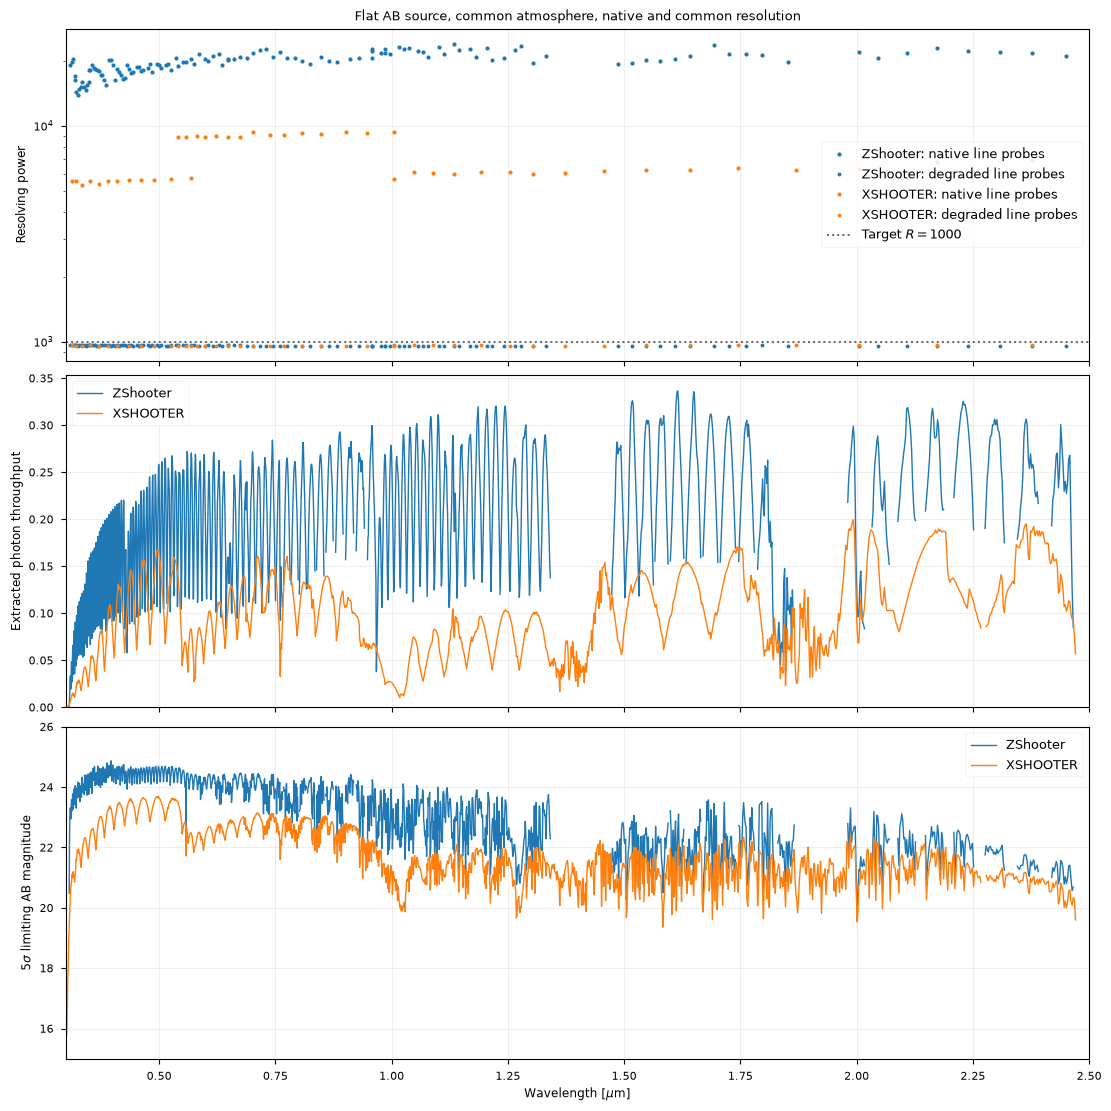

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True, layout='constrained')
colors = {'ZShooter': 'tab:blue', 'XSHOOTER': 'tab:orange'}
for name in trains:
    native = line_table[line_table.instrument == name].sort_values('wavelength_um')
    degraded = common_lines[common_lines.instrument == name].sort_values('wavelength_um')
    curve = comparison[comparison.instrument == name].sort_values('wavelength_um')
    axes[0].plot(native.wavelength_um, native.native_R, 'o', color=colors[name], ms=3, label=f'{name}: native line probes')
    axes[0].plot(degraded.wavelength_um, degraded.common_R_FWHM, '.', color=colors[name], label=f'{name}: degraded line probes')
    # Split true coverage gaps so the plot does not invent observations between arms.
    groups = (curve.element.diff() > 1).cumsum()
    for group, segment in curve.groupby(groups):
        axes[1].plot(segment.wavelength_um, segment.extracted_throughput, color=colors[name], lw=1, label=name if group == 0 else None)
        axes[2].plot(segment.wavelength_um, segment.limiting_AB_5sigma, color=colors[name], lw=1, label=name if group == 0 else None)
axes[0].axhline(TARGET_R, color='.4', ls=':', label=r'Target $R=1000$')
axes[0].set(ylabel='Resolving power', yscale='log', title='Flat AB source, common atmosphere, native and common resolution')
axes[1].set(ylabel='Extracted photon throughput', ylim=(0, None))
axes[2].set(ylabel=r'$5\sigma$ limiting AB magnitude', xlabel=r'Wavelength [$\mu$m]', ylim=(15, 26))
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=9)
axes[2].set_xlim(.3, 2.5)
fig.savefig(output / 'flat_ab_comparison.png', dpi=160)
plt.show()


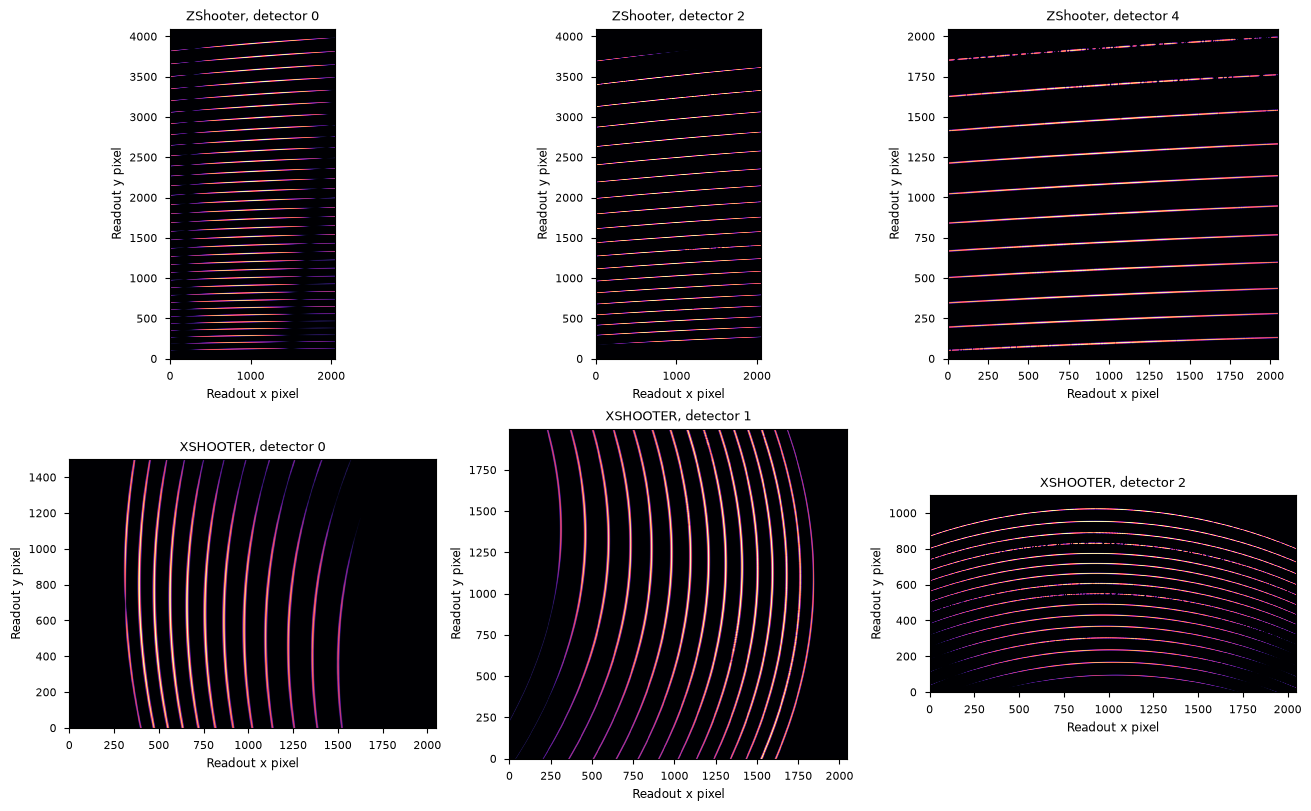

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout='constrained')
for row, name in enumerate(trains):
    selected_detectors = (0, 2, 4) if name == 'ZShooter' else (0, 1, 2)
    for ax, index in zip(axes[row], selected_detectors):
        source_image = frames[name][index]['source']
        scale = np.percentile(source_image[source_image > 0], 75)
        ax.imshow(np.arcsinh(source_image / scale), origin='lower', cmap='magma', aspect='equal', interpolation='nearest')
        ax.set(title=f'{name}, detector {index}', xlabel='Readout x pixel', ylabel='Readout y pixel')
fig.savefig(output / 'native_frames.png', dpi=140)
plt.show()


## Optional OH sample selection

This diagnostic keeps the same spatial extraction and selects native wavelength samples within intervals of width $\Delta\log\lambda=1/1000$. Samples are ranked by expected source signal divided by background variance; the cut maximizes the expected 5-sigma continuum limit including source shot noise. It is a hard spectral selection, not Horne extraction. The retained source fraction makes the cost visible.

The selected intervals have an irregular spectral response and are **not** the Gaussian-matched spectra above. Use these gains to assess whether OH avoidance is useful for a science case, then inspect line recovery and the retained samples before adopting it. The gain is relative to using every native sample in the same interval, not relative to a different instrument's smoothed curve.


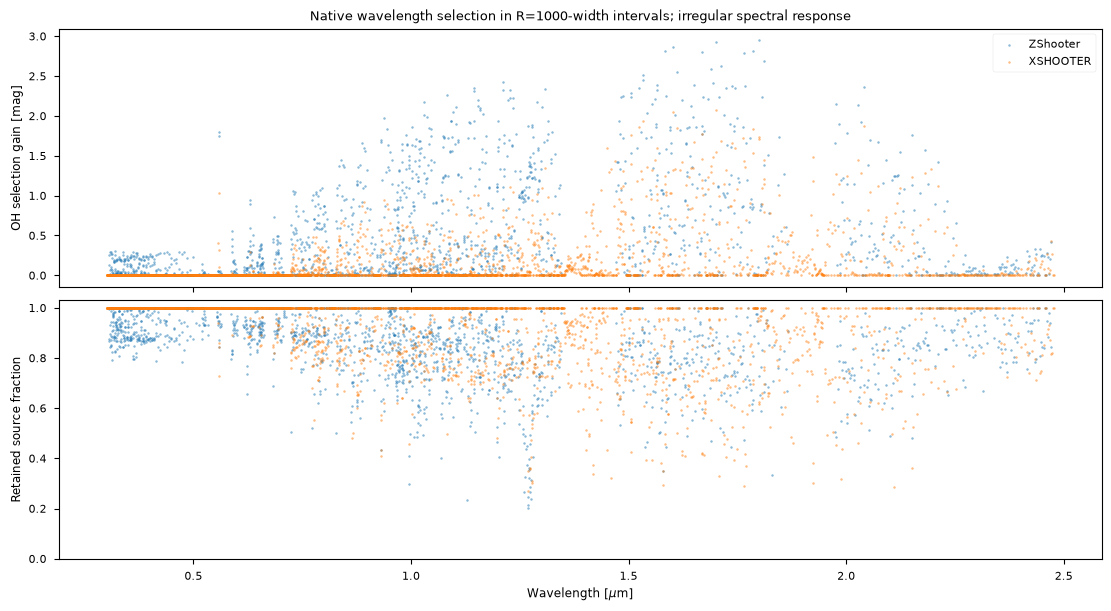

In [9]:
from zs_scopesim_tools.comparison import select_spectral_samples

oh_rows = []
for name in trains:
    for trace_id, data in extracted[name].items():
        wave = (data['edges'][:-1] + data['edges'][1:]) / 2
        for element in range(len(resolution_wave)):
            low, high = resolution_edges[element:element + 2]
            if low < data['edges'][0] or high > data['edges'][-1]:
                continue
            pixels = np.flatnonzero((wave >= low) & (wave < high))
            if len(pixels) < 2:
                continue
            signal = data['signal'][pixels]
            variance = data['variance_background'][pixels]
            if np.any(signal <= 0) or np.any(variance <= 0):
                continue
            selected, limit = select_spectral_samples(signal, variance, AB_MAG)
            full_limit = limiting_abmag(signal.sum(), signal.sum(), variance.sum(), AB_MAG)
            oh_rows.append((name, trace_id, resolution_wave[element].value, limit - full_limit, signal[selected].sum() / signal.sum(), len(selected), len(pixels)))
oh_table = pd.DataFrame(oh_rows, columns=['instrument', 'trace', 'wavelength_um', 'gain_mag', 'retained_source_fraction', 'samples_kept', 'samples_available'])
oh_table.to_csv(output / 'oh_selection.csv', index=False)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
for name in trains:
    data = oh_table[oh_table.instrument == name]
    axes[0].scatter(data.wavelength_um, data.gain_mag, s=2, alpha=.5, color=colors[name], label=name)
    axes[1].scatter(data.wavelength_um, data.retained_source_fraction, s=2, alpha=.5, color=colors[name])
axes[0].set(ylabel='OH selection gain [mag]', title='Native wavelength selection in R=1000-width intervals; irregular spectral response')
axes[1].set(ylabel='Retained source fraction', xlabel=r'Wavelength [$\mu$m]', ylim=(0, 1.03))
axes[0].legend()
fig.savefig(output / 'oh_selection.png', dpi=150)
plt.show()


## Optional color and science context

Keep the flat-AB run above as the technical reference. A G5V source for a separate context run is:

```python
from scopesim_templates.stellar import stars
context_source = stars(filter_name='V', amplitudes=[20.] * u.ABmag, spec_types=['G5V'], x=[0.] * u.arcsec, y=[0.] * u.arcsec)
```

Use the same configured trains and boxcar extraction in a separate notebook/output directory. Replace the incident-flux normalization with this source's actual spectrum before calculating throughput. A single amplitude change then means scaling that template; its limiting magnitude is not a flat-AB sensitivity curve. These optional context runs have not been executed here.

For kilonovae, use the existing [ZShooter source notebook](01_Kilonovae.ipynb) and [X-shooter companion](01_Kilonovae_XSHOOTER.ipynb) to define the same epoch, distance, ejecta model, and host field, then feed that source to both configured trains. Keep the common atmosphere and explicit nod/exposure convention. A structured-spectrum or extended-host run needs its own extraction and line-recovery assessment; scaling the flat-AB table alone does not simulate those effects.

The higher-resolution X-shooter preset uses 0.8/0.9/0.6 arcsec slits (manual nominal resolving powers 6700/8900/8100) and unbinned CCDs. Its narrower NIR slit trades throughput for resolution. Neither preset forces X-shooter's native data to R=1000: the common-resolution calculation is performed after native extraction.

## Check the extraction on noisy native frames

Subtract an independent equal-time simulated sky exposure, convert the difference to accumulated electrons using the actual gain and NIR averaging effects, and apply the same boxcars. Identical bias and mean dark cancel in the difference. Their statistical variance does not. The source and sky readouts use distinct explicit random-stream IDs, so reusing a fixed simulation seed cannot accidentally cancel read noise.

This tests extraction and variance accounting on noisy frames with a known sky, wavelength map and aperture. It is not a calibration or sky-fitting pipeline.


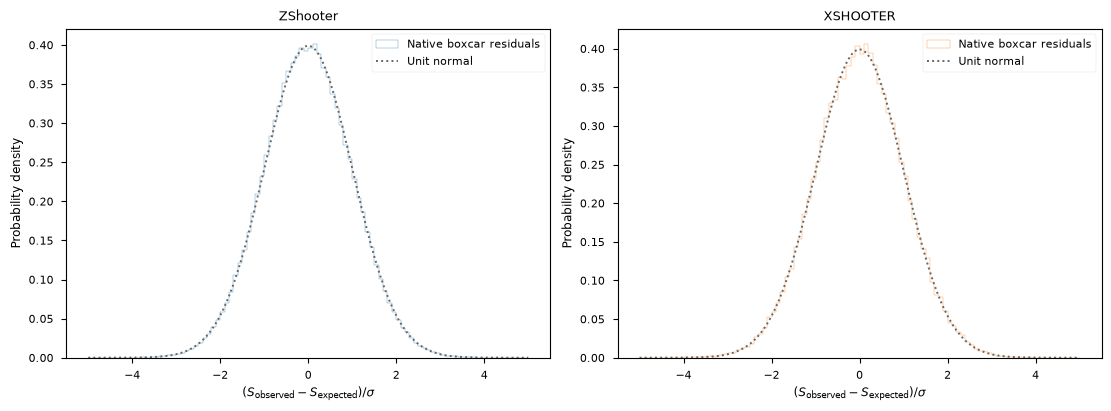

,instrument,native_samples,mean_standardized_residual,std_standardized_residual
0,ZShooter,259284,-0.001473,0.998097
1,XSHOOTER,79269,0.002131,1.001109


In [10]:
from scopesim.effects.electronic import ADConversion, ExposureOutput

residual_rows = []
noisy_extractions = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, (name, train) in zip(axes, trains.items()):
    residuals = []
    noisy_extractions[name] = {}
    for index, manager in enumerate(train.detector_managers):
        detector, = manager
        difference = fits.getdata(output / f'{name}_detector_{index}.fits', 1) - fits.getdata(output / f'{name}_sky_{index}.fits', 1)
        for effect in train.optics_manager.detector_effects:
            selected = effect.get_effect(detector.det_id) if isinstance(effect, SelectorWheel) else effect
            if isinstance(selected, ADConversion):
                difference *= selected._get_gain(detector.det_id)
            if isinstance(selected, ExposureOutput) and selected.current_mode == 'average':
                difference *= from_currsys(selected.meta['ndit'], train.cmds)
        for trace_id, data in extracted[name].items():
            if data['index'] != index:
                continue
            observed = boxcar_sum(difference, data['axis'], data['pixels'], data['centers'], data['widths'])
            variance = data['variance_source'] + data['variance_background']
            residuals.extend((observed - data['signal']) / np.sqrt(variance))
            noisy_extractions[name][trace_id] = observed
    residuals = np.array(residuals)
    residual_rows.append((name, len(residuals), residuals.mean(), residuals.std()))
    ax.hist(residuals, bins=np.linspace(-5, 5, 101), density=True, histtype='step', color=colors[name], label='Native boxcar residuals')
    xx = np.linspace(-5, 5, 501)
    ax.plot(xx, np.exp(-xx**2/2) / np.sqrt(2*np.pi), color='.4', ls=':', label='Unit normal')
    ax.set(title=name, xlabel=r'$(S_{\rm observed}-S_{\rm expected})/\sigma$', ylabel='Probability density')
    ax.legend(fontsize=8)
residual_table = pd.DataFrame(residual_rows, columns=['instrument', 'native_samples', 'mean_standardized_residual', 'std_standardized_residual'])
residual_table.to_csv(output / 'noisy_extraction.csv', index=False)
fig.savefig(output / 'noisy_extraction.png', dpi=150)
plt.show()
display(residual_table)
